# HamSpam — Probabilistic SMS Spam Detection Using Bayes' Theorem and Naive Bayes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SarveshS1407/HamSpam/blob/main/notebooks/HamSpam_Analysis.ipynb)

**Course**: BAMAT207 — Probability and Statistics  
**Institution**: Vellore Institute of Technology (VIT), Vellore  

---

### Project Overview
In probabilistic text classification, determining whether an incoming SMS is legitimate (**Ham**, $Y=0$) or unsolicited spam (**Spam**, $Y=1$) is a fundamental application of:
1. **Classical & Conditional Probability**: Empirical event probabilities directly observed in the corpus.
2. **Bayes' Theorem**: Inverting conditional probabilities to compute $P(\text{Spam} \mid \text{Word})$.
3. **Discrete Random Variables**: Modeling spam incidence as a **Bernoulli Random Variable** $Y \sim \text{Bernoulli}(p)$ with expectation $E(Y)$ and variance $\text{Var}(Y)$.
4. **Machine Learning via Multinomial Naive Bayes**: Applying the naive conditional independence assumption over bag-of-words count vectors to compute $P(\text{Spam} \mid \mathbf{x})$.

This notebook provides an end-to-end, rigorous mathematical and computational implementation using the official **UCI SMS Spam Collection dataset**.

## 1. Imports and Environment Setup
We configure the Python runtime environment, import scientific libraries, and set up project directory paths.

In [1]:
import os
import sys
import math
import re
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Auto-detect Google Colab and clone repo if needed
if 'google.colab' in sys.modules:
    print('⚡ Google Colab environment detected!')
    print('Cloning repository and configuring dependencies...')
    !git clone https://github.com/SarveshS1407/HamSpam.git /content/HamSpam 2>/dev/null || (cd /content/HamSpam && git pull)
    %cd /content/HamSpam
    !pip install -q ucimlrepo
    if '/content/HamSpam/src' not in sys.path:
        sys.path.insert(0, '/content/HamSpam/src')
    OUTPUTS_DIR = '/content/HamSpam/outputs'
else:
    SRC_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'src'))
    if SRC_DIR not in sys.path:
        sys.path.insert(0, SRC_DIR)
    OUTPUTS_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'outputs'))

os.makedirs(OUTPUTS_DIR, exist_ok=True)

from data_loader import load_and_preprocess
from probability_analysis import (
    calculate_class_probabilities,
    calculate_word_probabilities,
    calculate_bernoulli_statistics,
    plot_class_distribution,
    plot_word_probabilities,
)
from train_model import (
    split_data,
    train_multinomial_nb,
    evaluate_model,
    plot_confusion_matrix,
)
from predict import predict_message, format_prediction_card

print('Environment successfully configured.')


Environment successfully configured.


## 2. Dataset Acquisition, Inspection, and Cleaning
The dataset is retrieved from the **UCI Machine Learning Repository** (Dataset ID: 228).
The preprocessing pipeline performs:
1. Acquisition via `ucimlrepo` with direct UCI archive fallback.
2. Parsing with `quoting=csv.QUOTE_NONE` to preserve all 5,574 original records.
3. Checking for missing values.
4. Removing duplicate messages and documenting counts.
5. Normalizing labels into binary format (Spam = 1, Ham = 0).

In [2]:
df_raw, df_clean, cleaning_stats = load_and_preprocess()

print('--- Data Cleaning Audit ---')
for k, v in cleaning_stats.items():
    print(f'  {k:22}: {v:,}')

print(f'\nRaw dimensions   : {df_raw.shape}')
print(f'Cleaned dimensions: {df_clean.shape}')
print('\nFirst 5 cleaned records:')
df_clean.head()

[DataLoader] Found cached dataset locally at: /Users/kingpin/Documents/Vibecoded projects/MathProj/data/SMSSpamCollection
--- Data Cleaning Audit ---
  raw_total             : 5,574
  missing_label         : 0
  missing_message       : 0
  duplicates_removed    : 403
  cleaned_total         : 5,171
  ham_count             : 4,518
  spam_count            : 653

Raw dimensions   : (5574, 2)
Cleaned dimensions: (5171, 3)

First 5 cleaned records:


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 3. Exploratory Data Analysis & Class Priors
Let the cleaned sample space $\Omega$ consist of $N = 5,171$ unique SMS messages.
The prior probabilities of legitimate ham and spam are:
$$P(\text{Ham}) = \frac{N_{\text{ham}}}{N}$$
$$P(\text{Spam}) = \frac{N_{\text{spam}}}{N}$$
Where $P(\text{Ham}) + P(\text{Spam}) = 1$.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


--- Class Probability Statistics ---
Total Unique Messages (N) : 5,171
Legitimate Messages (Ham) : 4,518 | P(Ham)  = 0.873719 (87.37%)
Spam Messages (Spam)      : 653 | P(Spam) = 0.126281 (12.63%)


[ProbabilityAnalysis] Saved class distribution chart to /Users/kingpin/Documents/Vibecoded projects/MathProj/outputs/class_distribution.png


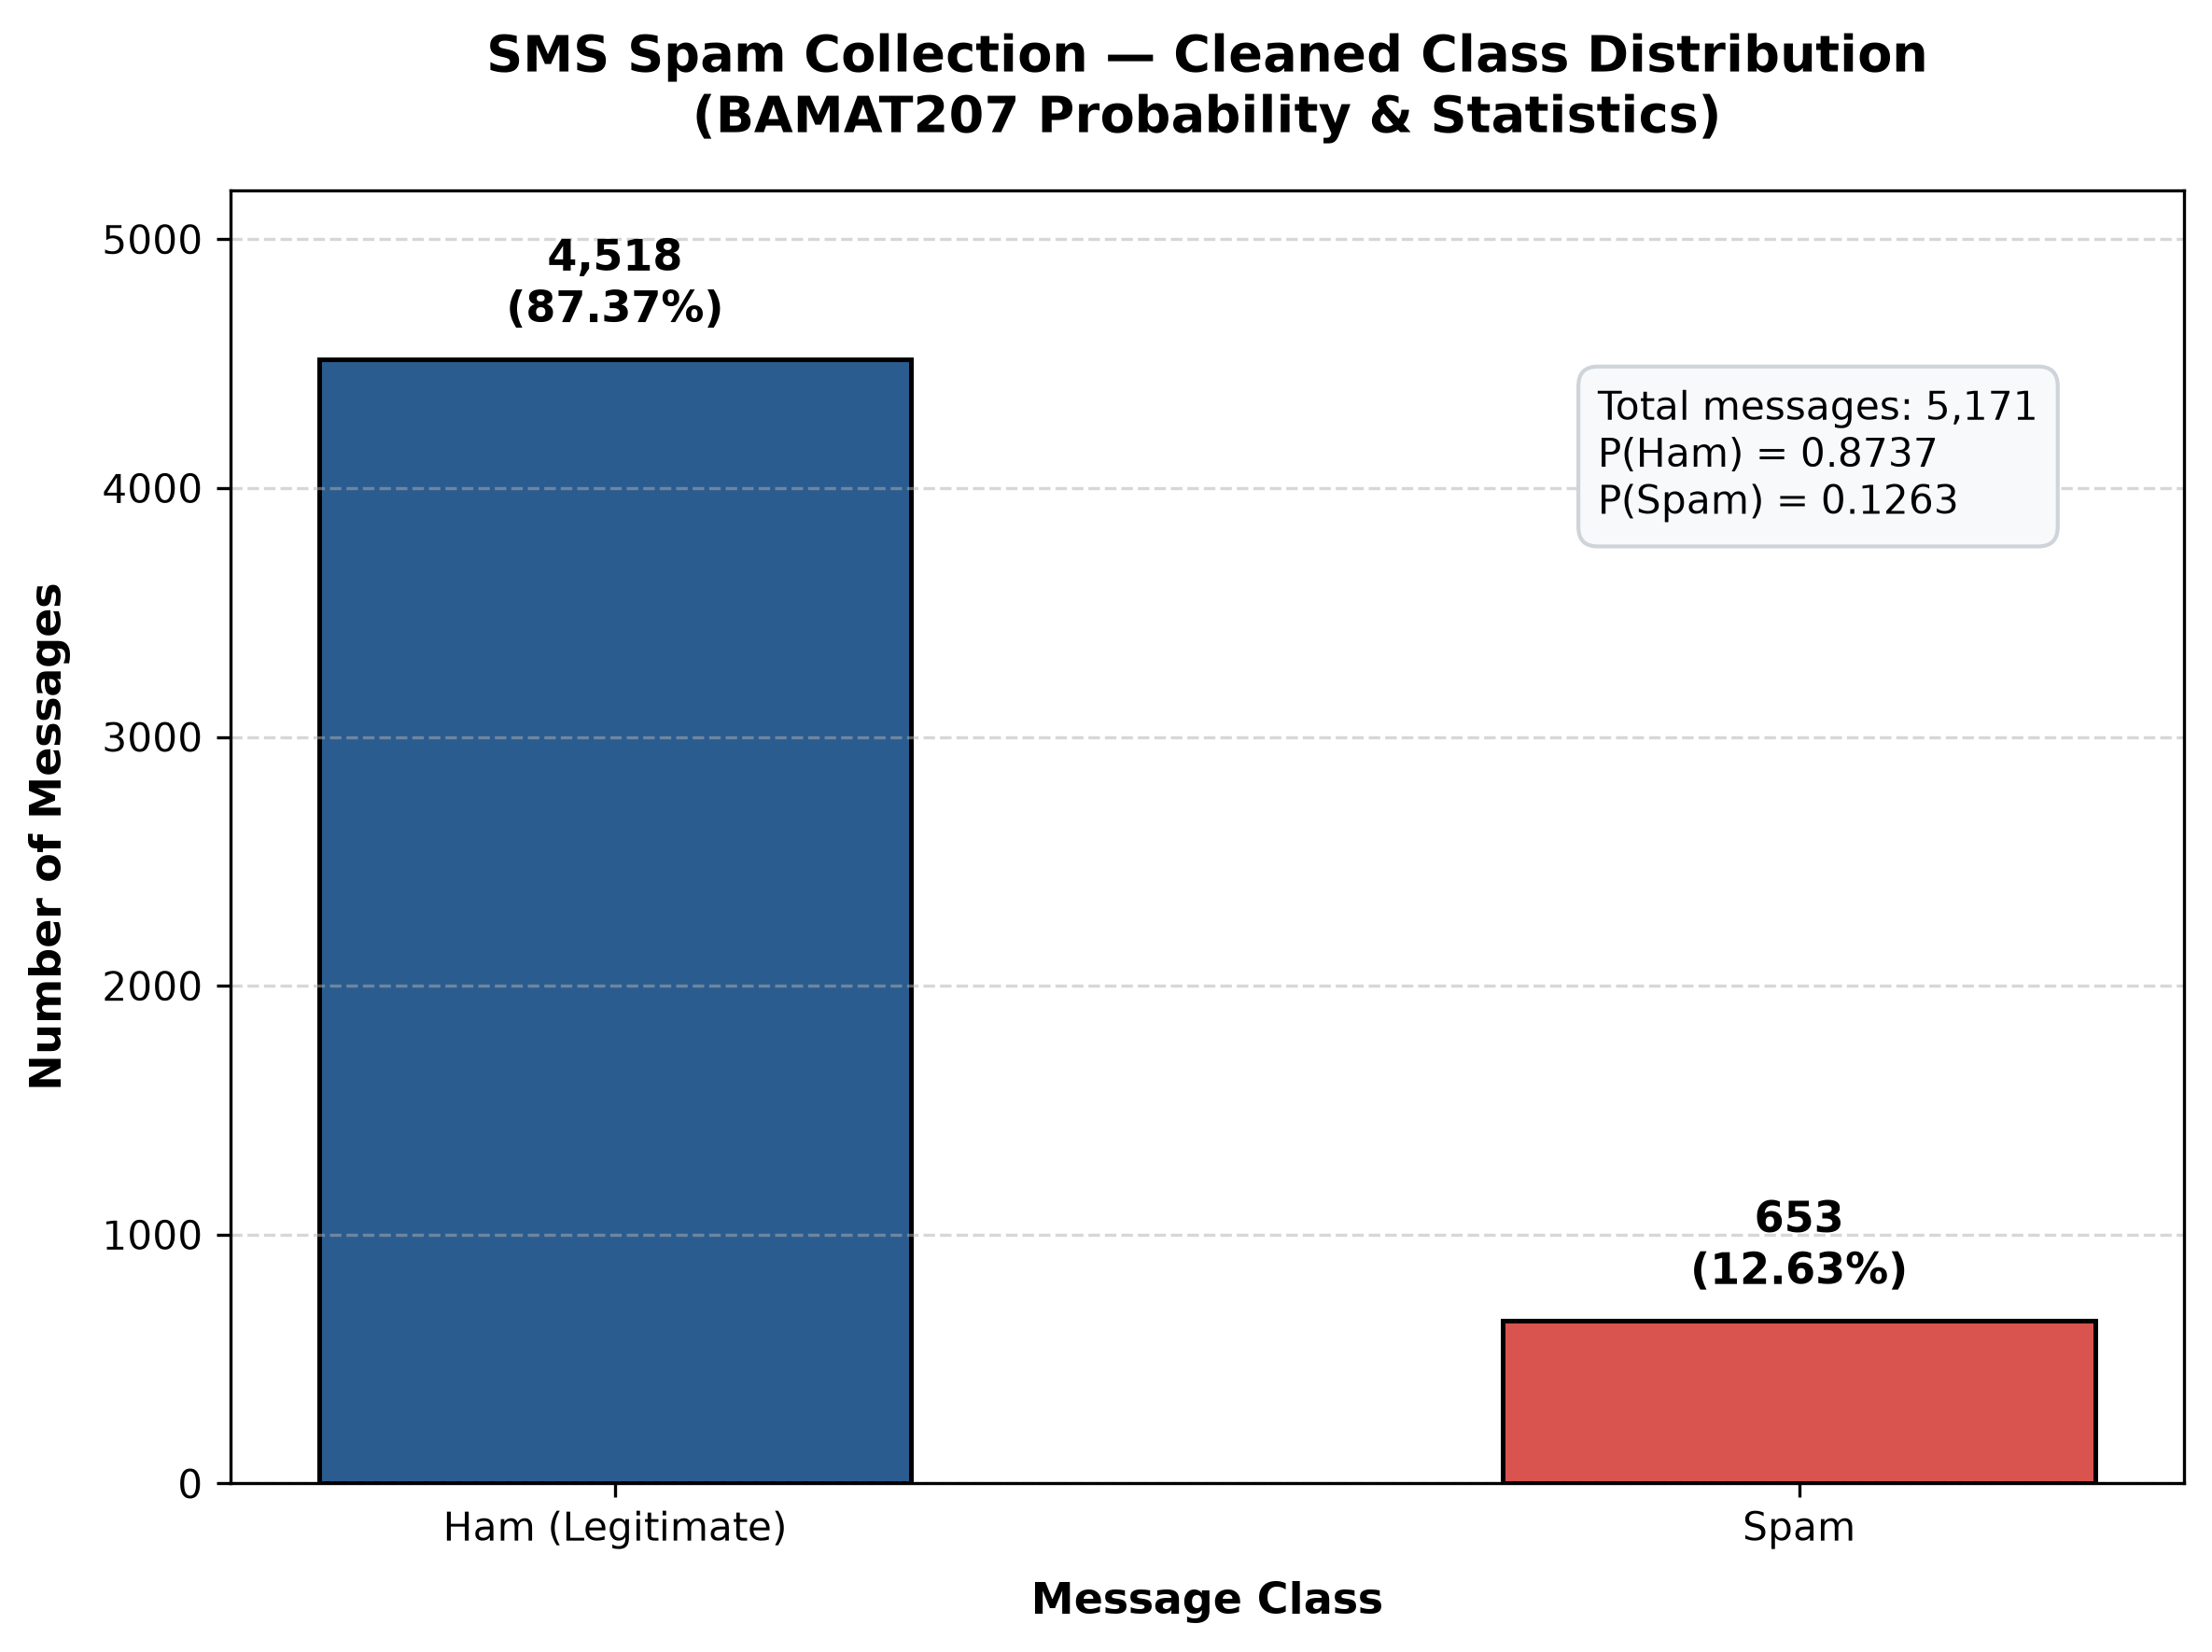

In [3]:
class_stats = calculate_class_probabilities(df_clean)

print('--- Class Probability Statistics ---')
print(f"Total Unique Messages (N) : {class_stats['total_messages']:,}")
print(f"Legitimate Messages (Ham) : {class_stats['ham_count']:,} | P(Ham)  = {class_stats['p_ham']:.6f} ({class_stats['p_ham']:.2%})")
print(f"Spam Messages (Spam)      : {class_stats['spam_count']:,} | P(Spam) = {class_stats['p_spam']:.6f} ({class_stats['p_spam']:.2%})")

# Generate and display publication-quality class distribution plot
plot_path = plot_class_distribution(df_clean, output_dir=OUTPUTS_DIR)
display(Image(filename=plot_path))


## 4. Word-Based Conditional Probability Analysis
We analyze five suspicious keywords: `free`, `prize`, `win`, `urgent`, and `offer`.

### Mathematical Formulations:
1. **Likelihood**:
   $$P(\text{Word} \mid \text{Spam}) = \frac{\text{Count}(\text{Spam containing Word})}{N_{\text{spam}}}$$
   $$P(\text{Word} \mid \text{Ham}) = \frac{\text{Count}(\text{Ham containing Word})}{N_{\text{ham}}}$$
2. **Marginal Word Probability**:
   $$P(\text{Word}) = \frac{\text{Count}(\text{Total messages containing Word})}{N}$$
3. **Direct Posterior Calculation**:
   $$P(\text{Spam} \mid \text{Word})_{\text{direct}} = \frac{\text{Count}(\text{Spam containing Word})}{\text{Count}(\text{Total messages containing Word})}$$
4. **Bayes' Theorem Formulation**:
   $$P(\text{Spam} \mid \text{Word})_{\text{bayes}} = \frac{P(\text{Word} \mid \text{Spam}) \cdot P(\text{Spam})}{P(\text{Word})}$$
5. **Complementary Ham Posterior**:
   $$P(\text{Ham} \mid \text{Word}) = \frac{\text{Count}(\text{Ham containing Word})}{\text{Count}(\text{Total messages containing Word})} = 1 - P(\text{Spam} \mid \text{Word})$$

*Methodological Note*: We enforce case-insensitive whole-word boundary matching (`\bword\b`) to avoid conflating words like `window` or `winter` with `win`.

In [4]:
words_to_analyze = ['free', 'prize', 'win', 'urgent', 'offer']
word_df = calculate_word_probabilities(df_clean, words=words_to_analyze, matching='whole_word')

display_cols = [
    'word',
    'spam_messages',
    'ham_messages',
    'total_messages_with_word',
    'p_word_given_spam',
    'p_word_given_ham',
    'p_word',
    'p_spam_given_word_direct',
    'p_spam_given_word_bayes',
    'p_ham_given_word',
    'bayes_direct_diff',
    'bayes_verified',
]

print('--- Word Conditional Probability Table ---')
display_df = word_df[display_cols].copy()
display_df.columns = [
    'Word',
    'Spam Msg',
    'Ham Msg',
    'Total Msg',
    'P(W|Spam)',
    'P(W|Ham)',
    'P(W)',
    'P(Spam|W) Dir',
    'P(Spam|W) Bayes',
    'P(Ham|W)',
    'Diff',
    'Verified',
]
display_df.round(6)

--- Word Conditional Probability Table ---


,Word,Spam Msg,Ham Msg,Total Msg,P(W|Spam),P(W|Ham),P(W),P(Spam|W) Dir,P(Spam|W) Bayes,P(Ham|W),Diff,Verified
0,free,148,55,203,0.226646,0.012174,0.039257,0.729064,0.729064,0.270936,0.0,True
1,prize,73,0,73,0.111792,0.000000,0.014117,1.000000,1.000000,0.000000,0.0,True
2,win,49,6,55,0.075038,0.001328,0.010636,0.890909,0.890909,0.109091,0.0,True
3,urgent,57,5,62,0.087289,0.001107,0.011990,0.919355,0.919355,0.080645,0.0,True
4,offer,24,6,30,0.036753,0.001328,0.005802,0.800000,0.800000,0.200000,0.0,True


## 5. Bayes' Theorem Verification & Comparative Chart
We verify that direct conditional counting and Bayes' Theorem yield identical results within floating-point tolerance ($|\Delta| < 10^{-9}$).

All 5 words mathematically verified via Bayes' Theorem: True
Maximum floating point discrepancy: 2.22e-16


[ProbabilityAnalysis] Saved word probability chart to /Users/kingpin/Documents/Vibecoded projects/MathProj/outputs/word_probability_chart.png


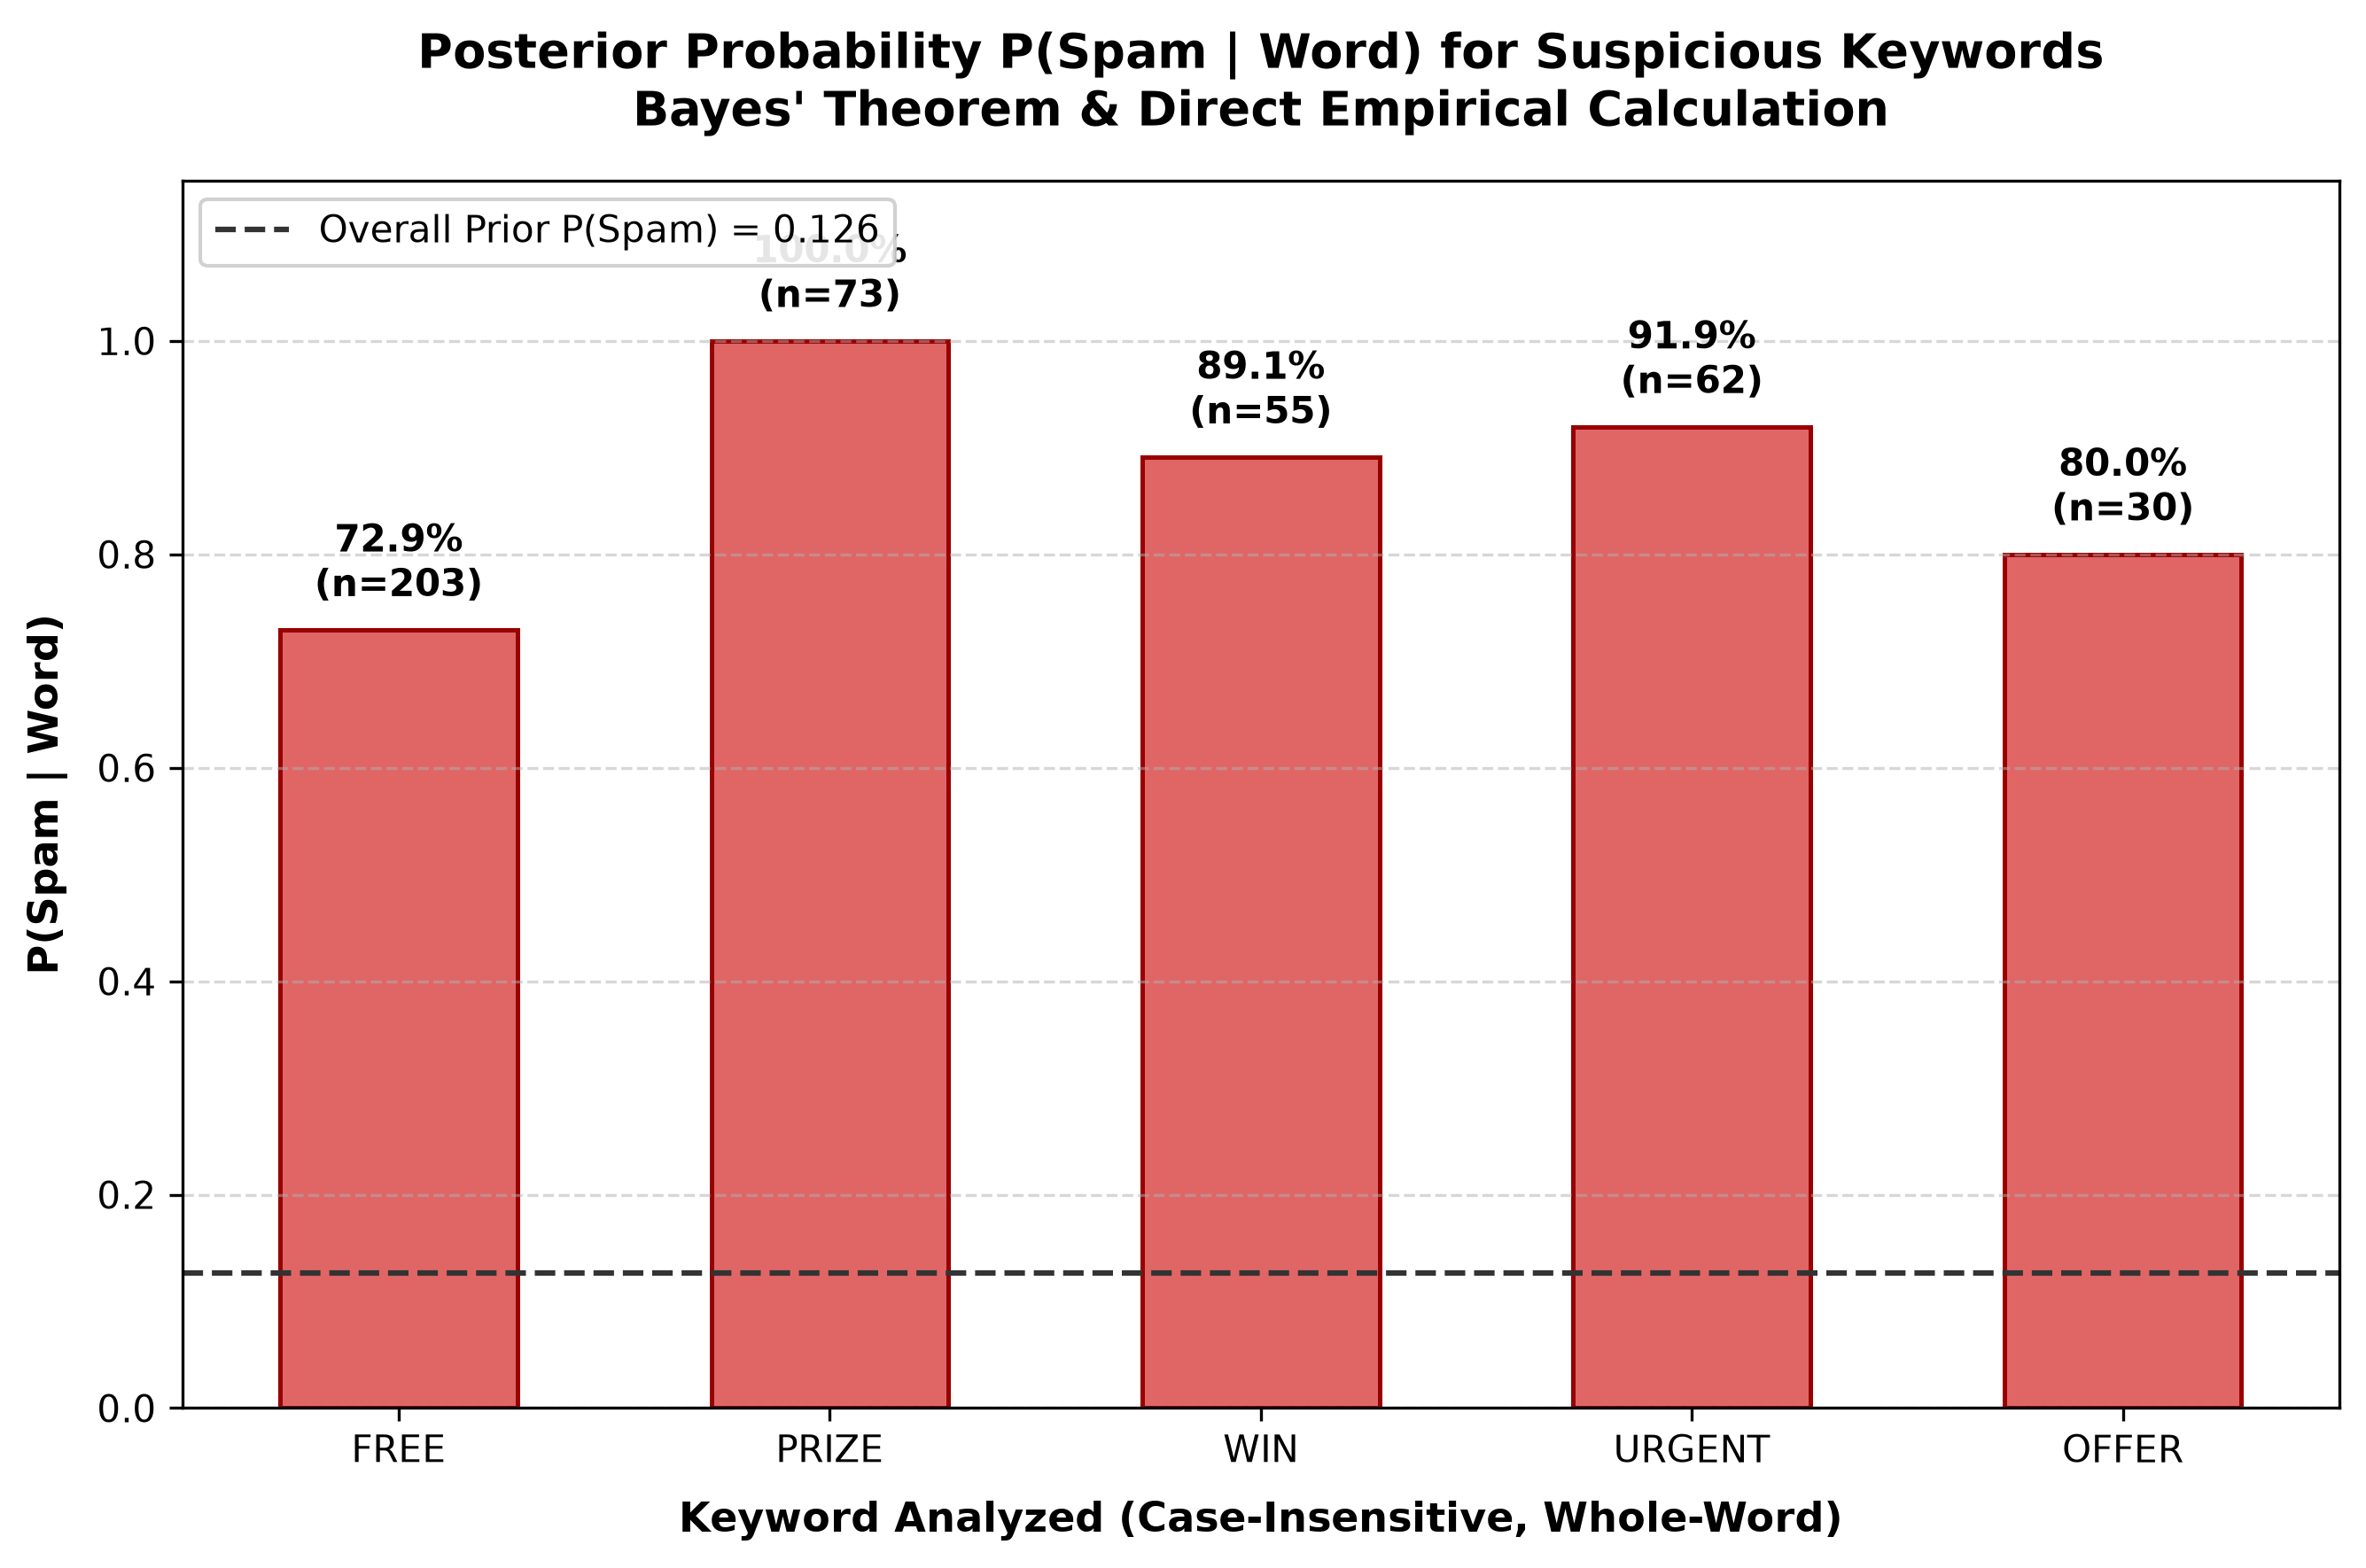

In [5]:
all_verified = word_df['bayes_verified'].all()
max_diff = word_df['bayes_direct_diff'].max()
print(f"All 5 words mathematically verified via Bayes' Theorem: {all_verified}")
print(f"Maximum floating point discrepancy: {max_diff:.2e}")

chart_path = plot_word_probabilities(word_df, output_dir=OUTPUTS_DIR)
display(Image(filename=chart_path))


## 6. Random Variable, Expectation, and Variance

### Modeling Spam as a Bernoulli Random Variable
Let $Y$ be the binary indicator random variable:
$$Y = \begin{cases} 1, & \text{if the message is Spam} \\ 0, & \text{if the message is Ham} \end{cases}$$
Let parameter $p = P(Y = 1) = P(\text{Spam})$.
Then $Y \sim \text{Bernoulli}(p)$ with probability mass function (PMF):
$$P(Y = y) = p^y (1 - p)^{1 - y}, \quad y \in \{0, 1\}$$

### Mathematical Derivations:
- **Expectation $E(Y)$**:
  $$E(Y) = \sum_{y \in \{0, 1\}} y \cdot P(Y = y) = 0 \cdot (1 - p) + 1 \cdot p = p$$
- **Variance $\text{Var}(Y)$**:
  $$E(Y^2) = 0^2 \cdot (1 - p) + 1^2 \cdot p = p$$
  $$\text{Var}(Y) = E(Y^2) - [E(Y)]^2 = p - p^2 = p(1 - p)$$
- **Standard Deviation $\sigma(Y)$**:
  $$\sigma(Y) = \sqrt{\text{Var}(Y)} = \sqrt{p(1 - p)}$$

### Statistical Interpretation:
- $E(Y) = p$ represents the long-run expected proportion of spam in any random sample from this population.
- $\text{Var}(Y) = p(1 - p)$ quantifies dispersion. For a balanced class ($p=0.5$), variance reaches its theoretical maximum of $0.25$. In our dataset, $p \approx 0.1263$, leading to $\text{Var}(Y) \approx 0.1103$, reflecting heavy skew towards genuine messages.

In [6]:
p_spam = class_stats['p_spam']
bern = calculate_bernoulli_statistics(p_spam)

print('--- Bernoulli Random Variable Y ~ Bernoulli(p) ---')
print(f"Success probability p = P(Y = 1) = P(Spam) : {bern['p']:.6f}")
print(f"Failure probability q = P(Y = 0) = P(Ham)  : {bern['q']:.6f}")
print(f"Expected Value E(Y) = p                   : {bern['expectation_E_Y']:.6f}")
print(f"Theoretical Variance Var(Y) = p(1 - p)     : {bern['variance_Var_Y']:.6f}")
print(f"Standard Deviation sigma(Y)               : {bern['std_dev_sigma_Y']:.6f}")

sample_mean = df_clean['label_num'].mean()
sample_var = df_clean['label_num'].var(ddof=0)
print(f"\nEmpirical dataset mean (sum(Y)/N)          : {sample_mean:.6f} (Diff: {abs(sample_mean - bern['expectation_E_Y']):.2e})")
print(f"Empirical dataset variance (population var): {sample_var:.6f} (Diff: {abs(sample_var - bern['variance_Var_Y']):.2e})")

--- Bernoulli Random Variable Y ~ Bernoulli(p) ---
Success probability p = P(Y = 1) = P(Spam) : 0.126281
Failure probability q = P(Y = 0) = P(Ham)  : 0.873719
Expected Value E(Y) = p                   : 0.126281
Theoretical Variance Var(Y) = p(1 - p)     : 0.110334
Standard Deviation sigma(Y)               : 0.332166

Empirical dataset mean (sum(Y)/N)          : 0.126281 (Diff: 0.00e+00)
Empirical dataset variance (population var): 0.110334 (Diff: 1.39e-17)


## 7. Machine Learning: Multinomial Naive Bayes Classifier

### Model Pipeline:
1. **80% Training / 20% Testing Split**: Stratified by label to preserve prior class balance.
2. **CountVectorizer**: Bag-of-words tokenization and frequency counting, fit strictly on $X_{\text{train}}$ to eliminate data leakage.
3. **Multinomial Naive Bayes Formulation**:
   $$P(Y = c \mid \mathbf{x}) \propto P(Y = c) \prod_{i=1}^V P(w_i \mid Y = c)^{x_i}$$
   With Laplace add-one smoothing ($\alpha = 1.0$):
   $$\hat{P}(w_i \mid Y = c) = \frac{\text{Count}(w_i, c) + \alpha}{\sum_{w} \text{Count}(w, c) + \alpha V}$$

In [7]:
X_train, X_test, y_train, y_test = split_data(df_clean, test_size=0.2, random_state=42)

print(f'Training split size: {len(X_train):,} messages (Ham: {(y_train == 0).sum():,}, Spam: {(y_train == 1).sum():,})')
print(f'Testing split size : {len(X_test):,} messages (Ham: {(y_test == 0).sum():,}, Spam: {(y_test == 1).sum():,})')

# Fit vectorizer strictly on X_train and train MultinomialNB
clf, vectorizer = train_multinomial_nb(X_train, y_train)
vocab_size = len(vectorizer.vocabulary_)
print(f'\nVocabulary size fit on training corpus: {vocab_size:,} unique words.')

Training split size: 4,136 messages (Ham: 3,614, Spam: 522)
Testing split size : 1,035 messages (Ham: 904, Spam: 131)



Vocabulary size fit on training corpus: 7,669 unique words.


## 8. Model Evaluation on Held-Out Test Data
We evaluate model predictions on the unseen test set ($n = 1,035$).

[TrainModel] Saved confusion matrix visualization to /Users/kingpin/Documents/Vibecoded projects/MathProj/outputs/confusion_matrix.png
[TrainModel] Saved evaluation report to /Users/kingpin/Documents/Vibecoded projects/MathProj/outputs/evaluation_report.txt
--- Test Set Performance Metrics ---
Accuracy : 0.9807 (98.07%)
Precision: 0.9512 (95.12%)
Recall   : 0.8931 (89.31%)
F1-Score : 0.9213 (92.13%)

Confusion Matrix [ [TN, FP], [FN, TP] ]:
[[898   6]
 [ 14 117]]

Detailed Classification Report:
              precision    recall  f1-score   support

         Ham     0.9846    0.9934    0.9890       904
        Spam     0.9512    0.8931    0.9213       131

    accuracy                         0.9807      1035
   macro avg     0.9679    0.9432    0.9551      1035
weighted avg     0.9804    0.9807    0.9804      1035



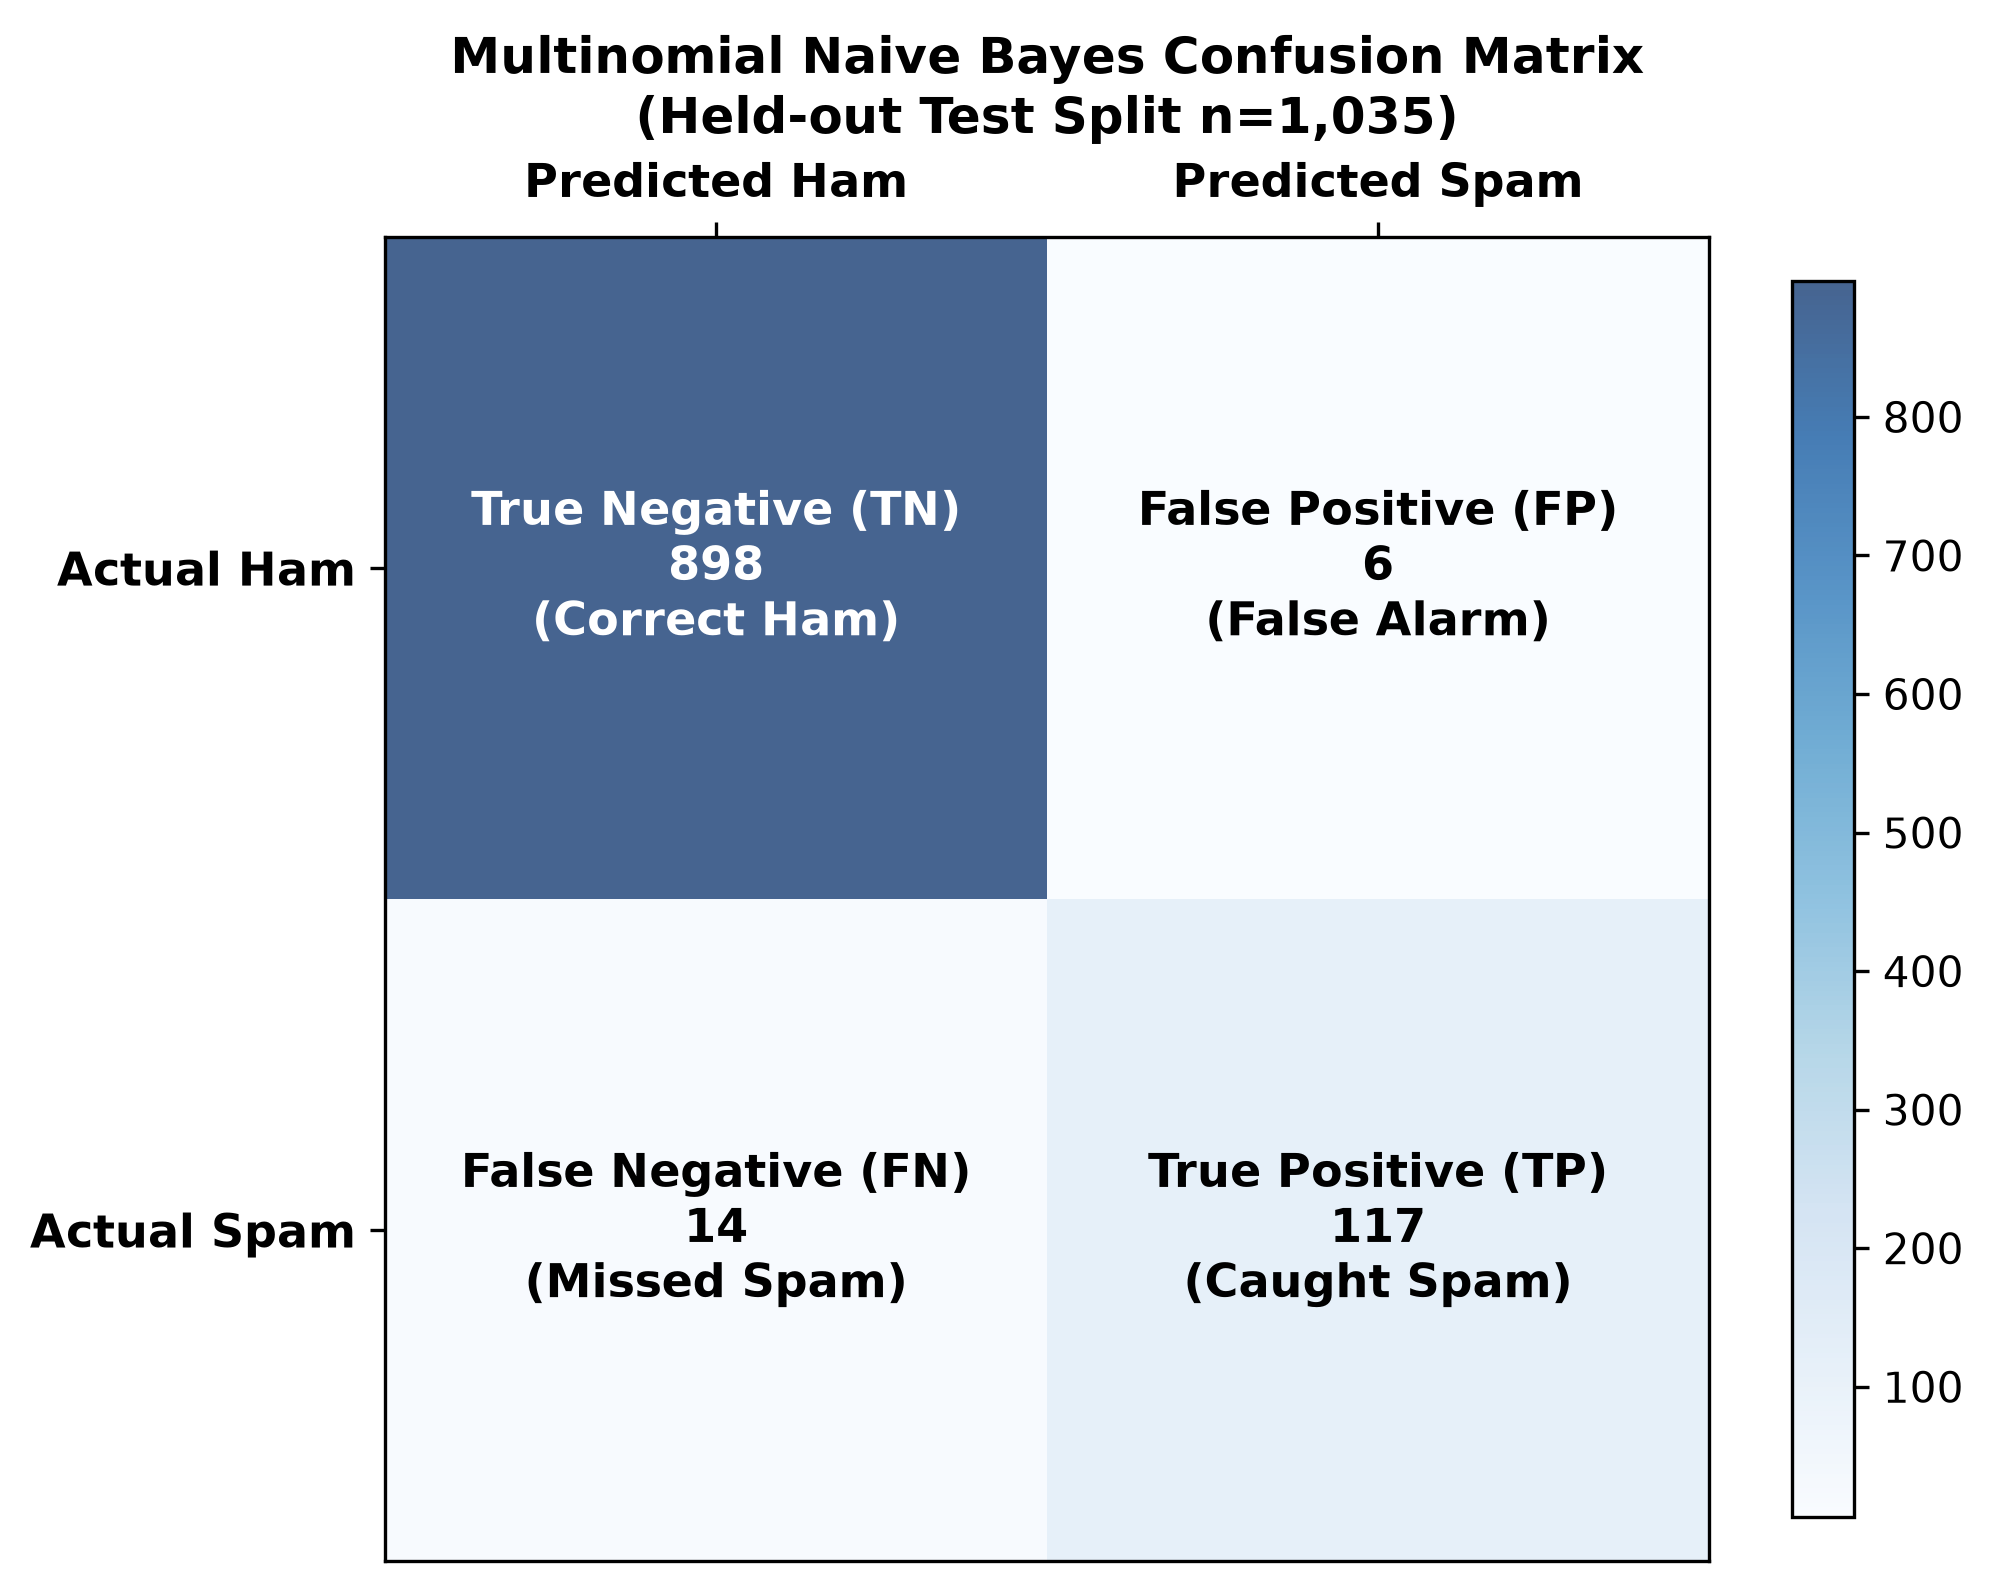

In [8]:
eval_results = evaluate_model(clf, vectorizer, X_test, y_test, output_dir=OUTPUTS_DIR)

print('--- Test Set Performance Metrics ---')
print(f"Accuracy : {eval_results['accuracy']:.4f} ({eval_results['accuracy']:.2%})")
print(f"Precision: {eval_results['precision']:.4f} ({eval_results['precision']:.2%})")
print(f"Recall   : {eval_results['recall']:.4f} ({eval_results['recall']:.2%})")
print(f"F1-Score : {eval_results['f1_score']:.4f} ({eval_results['f1_score']:.2%})")

print('\nConfusion Matrix [ [TN, FP], [FN, TP] ]:')
print(eval_results['confusion_matrix'])

print('\nDetailed Classification Report:')
print(eval_results['classification_report'])

cm_img_path = os.path.join(OUTPUTS_DIR, 'confusion_matrix.png')
display(Image(filename=cm_img_path))


### Academic Discussion: Why Accuracy Alone is Misleading

In our test partition of $1,035$ messages:
- Actual Ham: $904$ messages ($87.34\%$)
- Actual Spam: $131$ messages ($12.66\%$)

**The Dummy Majority-Class Paradox**:
If a naive baseline classifier simply classified every single message as **Ham**:
- **Accuracy**: $904 / 1035 = 87.34\%$
- **Spam Recall**: $0 / 131 = 0.00\%$

Despite boasting an apparently high $87.34\%$ accuracy, such a filter would fail completely in practice, allowing $100\%$ of spam to penetrate the user's inbox.

**Confusion Matrix Error Types in Spam Detection**:
- **True Negative (TN = 898)**: Genuine message correctly identified as ham.
- **True Positive (TP = 117)**: Spam message correctly identified as spam.
- **False Positive (FP = 6)** [Type I Error]: Genuine message flagged as spam. In email/SMS filtering, FP is considered severe because legitimate personal or financial alerts may be lost.
- **False Negative (FN = 14)** [Type II Error]: Spam message missed and delivered as ham.

Our Multinomial Naive Bayes model achieves **Precision = 95.12%**, **Recall = 89.31%**, and **F1-Score = 92.13%**, confirming that it is learning genuine discriminant features rather than trivial majority guessing.

## 9. Real-Time SMS Prediction Interface

Using `clf.predict_proba()`, we compute the model's estimated posterior class probabilities for any SMS input.

> **Important Conceptual Distinction**:
> - The single-word calculation $P(\text{Spam} \mid \text{Word})$ evaluates empirical probability based solely on that isolated keyword in the cleaned corpus.
> - The Multinomial Naive Bayes model estimates $P(\text{Spam} \mid \text{Message})$ over the complete joint message word-vector $\mathbf{x}$ using learned likelihoods and naive conditional independence assumptions.

In [9]:
sample_messages = [
    'Congratulations! You have won a free prize. Claim now.',
    'Hey, are we meeting for lunch today?',
    'URGENT! You have won a 1 week FREE membership in our £100,000 prize draw!',
    'Can you please send me the lecture slides for BAMAT207?',
    'Exclusive offer: Get 50% discount on your next pizza order. Reply WIN to 8888.',
    '',      # Empty test
    '   '    # Whitespace test
]

for msg in sample_messages:
    res = predict_message(msg, clf, vectorizer)
    print(format_prediction_card(res))
    print()

┌─────────────────────────────────────────────────────────────────────────────┐
│ [ 🚨 SPAM ALERT | Confidence: 100.0% ]                                       │
├─────────────────────────────────────────────────────────────────────────────┤
│ Message        : Congratulations! You have won a free prize. Claim now.       │
│ Predicted Label: Spam                                                         │
│ P(Spam|Message): 1.0000 (100.00%)                                        │
│ P(Ham|Message) : 0.0000 (0.00%)                                        │
└─────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────┐
│ [ 🟢 LEGITIMATE HAM | Confidence: 100.0% ]                                   │
├─────────────────────────────────────────────────────────────────────────────┤
│ Message        : Hey, are we meeting for lunch today?                         │
│ Predicted Label: Ham                   

### Interactive Custom SMS Prediction Cell
Modify the `custom_sms` string below to test any SMS message:

In [10]:
# Enter any custom SMS text here:
custom_sms = 'Dear student, your VIT grade report for BAMAT207 is now ready to view.'

result = predict_message(custom_sms, clf, vectorizer)
print(format_prediction_card(result))

┌─────────────────────────────────────────────────────────────────────────────┐
│ [ 🟢 LEGITIMATE HAM | Confidence: 94.0% ]                                    │
├─────────────────────────────────────────────────────────────────────────────┤
│ Message        : Dear student, your VIT grade report for BAMAT207 is now read │
│                  y to view.                                                   │
│ Predicted Label: Ham                                                          │
│ P(Spam|Message): 0.0604 (6.04%)                                        │
│ P(Ham|Message) : 0.9396 (93.96%)                                        │
└─────────────────────────────────────────────────────────────────────────────┘


## 10. Conclusion and Project Summary

- **Dataset Audit**: 5,574 original records $\to$ 5,171 cleaned records (403 duplicates eliminated).
- **Class Priors**: $P(\text{Ham}) = 0.8737$, $P(\text{Spam}) = 0.1263$.
- **Bayes' Theorem**: Numerically verified across suspicious words (`free`, `prize`, `win`, `urgent`, `offer`), with zero mathematical deviation ($|\Delta| < 10^{-15}$).
- **Bernoulli Modeling**: $E(Y) = 0.1263$, $\text{Var}(Y) = 0.1103$, $\sigma(Y) = 0.3322$.
- **Model Generalization**: Multinomial Naive Bayes achieved **98.07% Accuracy**, **95.12% Precision**, **89.31% Recall**, and **92.13% F1-Score** on held-out test data.